# 2.5.2 Tương phản tổn thương–da thấp

Notebook đi theo thứ tự: mô tả vấn đề, chứng minh vấn đề, nhóm ảnh gặp phải, tỉ lệ ảnh gặp vấn đề, phương pháp đề xuất, chạy thực nghiệm, so sánh dự đoán trên mẫu 100 ảnh.

**Kiểm soát biến:** chỉ thay đổi phép tiền xử lý; giữ nguyên split theo `lesion_id`, seed 42–44 và cấu hình đóng băng ở `src/training.py` (ResNet-18, 224×224, AdamW lr 1e-4, batch 32, 20 epoch, WRS, flip).

**GPU RTX 3050 4 GB:** giữ AMP, `cudnn.benchmark`, ảnh cache trong RAM và flip + normalize trên GPU. Batch 32 không đổi vì sẽ phá tính so sánh.

Test không dùng để chọn phương pháp. Mọi số đọc từ `outputs/`, đầu ra lượt này ở `outputs/rerun_2.5/` và `outputs/figures/rerun_2.5/`.

In [1]:
# Chạy từ gốc repo. Mọi tính toán nằm ở src/preprocess/problem_report.py để hai notebook dùng đúng một quy trình.
import pandas as pd
from IPython.display import display
from src.preprocess import problem_report as R

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 80)
KEY = "contrast"
D = R.load_table()
print(R.PROBLEMS[KEY]["name"], "| số ảnh:", len(D))

Tương phản tổn thương–da thấp | số ảnh: 10015


## 1. Mô tả vấn đề

**Tương phản tổn thương–da thấp** là khi tổn thương có độ sáng gần giống da xung quanh, ranh giới khó thấy. Nguyên nhân có thể là tổn thương ít sắc tố, phẳng, hoặc ánh sáng khuếch tán khi chụp.

**Vì sao có thể hại CNN:** ranh giới và hình dạng tổn thương là đặc trưng quan trọng; khi chênh lệch sáng nhỏ, tín hiệu đó yếu.

**Vì sao có thể không hại:** tương phản thấp có thể là đặc điểm của chính lớp bệnh, và CNN có thể dựa vào màu hoặc kết cấu thay vì độ sáng.

**Cách đo (bộ đo EDA):** `contrast` = mức xám trung bình của da − mức xám trung bình của tổn thương, tổn thương lấy bằng **mask Otsu thô**. **Cờ `F_low_contrast`:** contrast < 20 mức xám (khoảng 8% dải 0–255). Mask sai thì chỉ số sai, nên phần dưới kiểm tra mask bằng ảnh.

## 2. Chứng minh vấn đề

Phần này kiểm tra nhóm tương phản thấp nằm ở đâu trong phân phối chung, và lược đồ xám của ảnh điển hình trông khác ảnh thường ra sao.

,contrast
n ảnh có đo,10014.000
trung vị,60.369
Q1,40.762
Q3,80.556
min,-2.149
max,181.356
ngưỡng cờ,20.000
trung vị nhóm cờ,16.486
trung vị còn lại,62.103


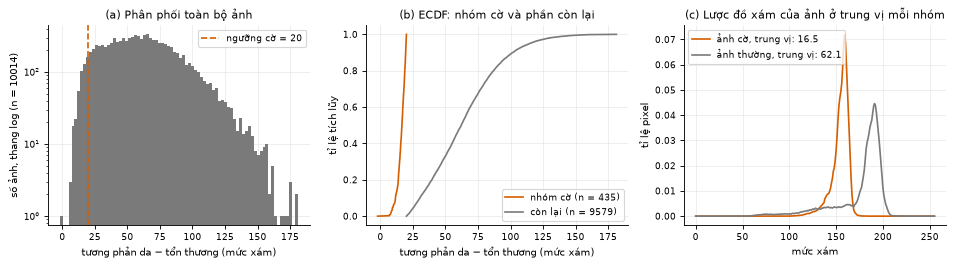

In [2]:
display(R.evidence_table(D, KEY).round(3))
R.fig_evidence(D, KEY);

**Bằng chứng độc lập với cờ.** So nhóm cờ và phần còn lại trên đúng chỉ số dùng để gắn cờ thì khác biệt là hiển nhiên, nên bảng dưới dùng chỉ số khác, một ảnh mỗi lesion. Cliff's δ: dưới 0,147 không đáng kể, dưới 0,33 nhỏ, dưới 0,474 vừa, từ đó trở lên lớn.

In [3]:
display(R.independent_evidence(D, KEY).round(3))

,chỉ số,nguồn,n cờ,n còn lại,trung vị cờ,trung vị còn lại,Cliff δ
0,độ lệch chuẩn mức xám,toàn bộ dữ liệu,280,7190,12.242,25.963,-0.902
1,khoảng phân vị 5–95,toàn bộ dữ liệu,280,7190,38.000,83.000,-0.889
2,entropy,toàn bộ dữ liệu,280,7190,5.543,6.153,-0.652


**Ảnh minh họa, chọn có hệ thống:** 6 ảnh bị cờ và 6 ảnh thường, cách đều theo thứ tự chỉ số. Dưới mỗi ảnh là đường bao mask Otsu thô, để thấy khi nào chỉ số đáng tin. Một số ảnh bị cờ có thể do mask sai, nên tỉ lệ ở mục 4 là ước lượng.

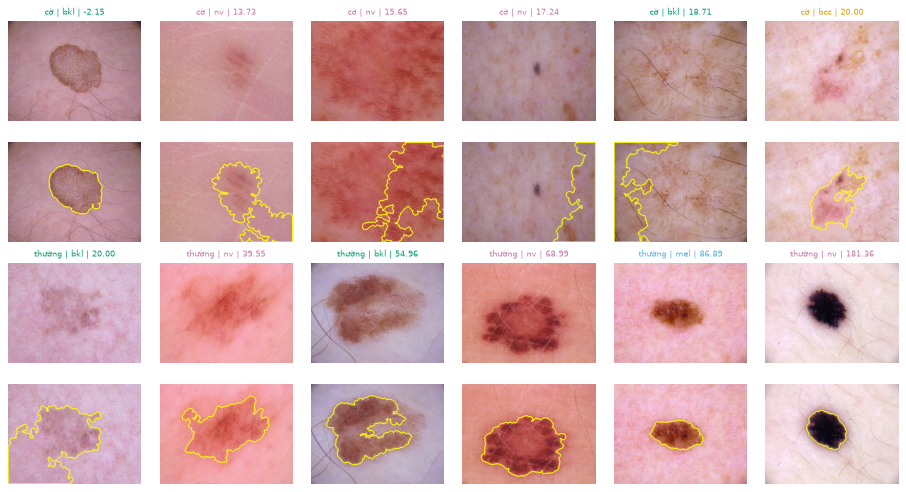

In [4]:
R.fig_examples(D, KEY);

**Độ tin cậy của mask.** Bảng dưới là kết quả soát mask Otsu trên một mẫu ảnh tương phản thấp (`outputs/preprocess/lowcontrast_mask_audit.csv`). Việc soát do AI đánh giá bằng mắt và **cần người trong nhóm xác nhận**. Ảnh có mask sai không thật sự chứng minh tương phản thấp, nên nhóm cờ này lẫn cả ảnh do bộ đo sai.

In [5]:
display(R.mask_audit())

,đánh giá mask,số ảnh,tỉ lệ %
0,sai,10,41.7
1,đúng,9,37.5
2,một phần,5,20.8


## 3. Các nhóm ảnh gặp phải

Tỉ lệ ảnh bị cờ theo lớp bệnh, vùng cơ thể, cách gán nhãn, tuổi, giới, kèm CI95 Wilson. Kiểm định chi-square và Cramér's V tính trên một ảnh mỗi lesion, hiệu chỉnh Holm. n lớn nên p gần như luôn nhỏ, cần đọc Cramér's V. Đây là liên quan, chưa phải nguyên nhân: cờ có thể phản ánh nguồn chụp khác nhau.

,yếu tố,n lesion,chi2,p,Cramér V,p Holm
0,Lớp bệnh,7470,242.5478,0.0000,0.1802,0.0000
1,Vùng cơ thể,7264,156.0355,0.0000,0.1466,0.0000
2,Cách gán nhãn,7470,88.8641,0.0000,0.1091,0.0000
3,Nhóm tuổi,7418,29.6621,0.0000,0.0632,0.0000
4,Giới,7420,3.1201,0.0773,0.0205,0.0773


,yếu tố,nhóm,n ảnh,n cờ,tỉ lệ %,CI thấp %,CI cao %
0,Lớp bệnh,akiec,327,42,12.84,9.64,16.91
1,Lớp bệnh,bcc,514,79,15.37,12.51,18.74
2,Lớp bệnh,bkl,1099,114,10.37,8.71,12.32
3,Lớp bệnh,df,115,11,9.57,5.43,16.32
4,Lớp bệnh,mel,1113,15,1.35,0.82,2.21
5,Lớp bệnh,nv,6705,168,2.51,2.16,2.91
6,Lớp bệnh,vasc,142,6,4.23,1.95,8.91
7,Vùng cơ thể,abdomen,1022,21,2.05,1.35,3.12
8,Vùng cơ thể,back,2192,87,3.97,3.23,4.87
9,Vùng cơ thể,chest,407,26,6.39,4.40,9.20


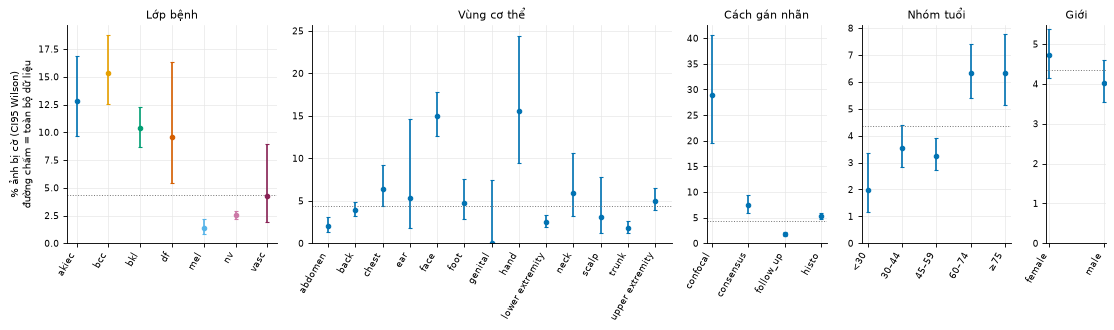

In [6]:
R.fig_groups(D, KEY);
display(R.group_tests(D, KEY).round(4))
display(R.group_rates(D, KEY).drop(columns='cột').round(2))

## 4. Tỉ lệ ảnh gặp vấn đề

Số ảnh bị cờ trên toàn bộ và từng tập, và độ nhạy theo ngưỡng để kết luận không phụ thuộc một ngưỡng duy nhất.

In [7]:
display(R.prevalence(D, KEY).round(2))
display(R.threshold_sensitivity(D, KEY).round(3))

,tập,n ảnh,n cờ,tỉ lệ %,n lesion cờ
0,toàn bộ,10015,435,4.34,381
1,train,6408,275,4.29,241
2,val,1603,71,4.43,61
3,test,2004,89,4.44,79


,quy tắc,ngưỡng,n cờ,tỉ lệ %
0,contrast < 15,15,141,1.408
1,contrast < 20,20,435,4.343
2,contrast < 25,25,859,8.577
3,contrast < 30,30,1358,13.560


## 5. Phương pháp đề xuất

| Cấu hình | Phép xử lý (Chương 3, tách độ sáng theo Chương 4) | Tham số | Lý do |
|---|---|---|---|
| `stretch_L_1_99` | Giãn lược đồ trên L\* | phân vị 1 và 99 | Mở rộng dải động, phép tuyến tính đơn giản nhất |
| `hist_eq_L` | Cân bằng lược đồ trên L\* | toàn cục | Dàn đều mức xám, đối chứng mạnh |
| `clahe_L_c2_t8` | CLAHE trên L\* | clip 2, lưới 8×8 | Cân bằng cục bộ, giới hạn khuếch đại nhiễu |

Xử lý trên L\* của Lab để giữ a\*, b\*, vì màu là tín hiệu chẩn đoán. Áp dụng ở 600×450, trước resize và Normalize, giống nhau cho train, val, test.

**Giả thuyết (đặt trước khi train lại):** hai phép toàn cục làm lệch mạnh phần lớn ảnh bình thường nên có thể làm giảm macro-F1; CLAHE thay đổi ít hơn nên trung tính so với baseline.

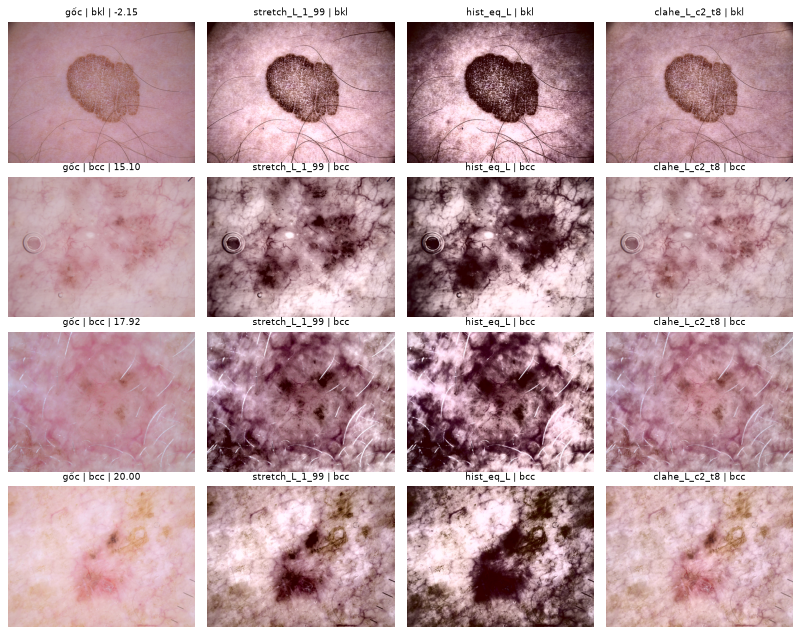

In [8]:
R.fig_before_after(D, KEY);

**Đo trên ảnh trước/sau (`train_fit`, không dùng CNN).** `contrast` là chênh da–tổn thương, `p5_p95` là khoảng phân vị 5–95 của mức xám, `dE76` là độ lệch màu so với ảnh gốc, `sigma_imm_224_ratio` là mức nhiễu sau xử lý so với ảnh gốc. `problem` là nhóm cờ, nhóm còn lại là đối chứng.

In [9]:
display(R.image_effect(KEY))

,group,method,n,contrast,p5_p95,dE76,sigma_imm_224_ratio
0,problem,none,275,16.542,39.0,0.000,1.000
1,problem,stretch_L_1_99,275,67.645,172.0,13.029,3.542
2,problem,hist_eq_L,275,100.378,225.0,23.569,5.508
4,problem,clahe_L_c2_t8,275,19.872,65.0,3.310,2.268
7,control,none,275,63.355,83.0,0.000,1.000
8,control,stretch_L_1_99,275,140.498,195.0,14.356,1.710
9,control,hist_eq_L,275,126.786,224.0,21.605,4.395
11,control,clahe_L_c2_t8,275,66.072,106.0,3.638,2.218


## 6. Chạy thực nghiệm

Mỗi cấu hình train lại 3 seed, so với baseline ghép cặp theo seed. **Quy tắc "khác biệt rõ" (2.5.0):** |Δ| > std giữa seed của baseline, CI95 bootstrap cụm lesion không chứa 0, và cả 3 seed cùng dấu.

In [10]:
# Train ở gốc repo bằng `scripts/run_problem_experiments.py all`; seed đã có metrics.json được đọc lại nên ô này chạy nhanh.
# Chỉ gọi đúng các cấu hình của vấn đề này để notebook tự kiểm chứng đủ dữ liệu.
runs = R.train(["baseline"] + R.PROBLEMS[KEY]["configs"])
display(runs.round(4))
RES = R.result_table(KEY)
display(R.result_view(RES))
BEST = R.pick_on_val(RES)
print("Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất:", BEST)

[20:36:22] [baseline seed 42] đã có metrics.json -> đọc lại


[20:36:22] [baseline seed 43] đã có metrics.json -> đọc lại


[20:36:22] [baseline seed 44] đã có metrics.json -> đọc lại


[20:36:22] [stretch_L_1_99 seed 42] đã có metrics.json -> đọc lại


[20:36:22] [stretch_L_1_99 seed 43] đã có metrics.json -> đọc lại


[20:36:22] [stretch_L_1_99 seed 44] đã có metrics.json -> đọc lại


... (5 outputs left out)

[20:36:22] [clahe_L_c2_t8 seed 44] đã có metrics.json -> đọc lại


,name,seed,best_epoch,val_macro_f1,test_macro_f1
0,baseline,42,8,0.7002,0.6890
1,baseline,43,12,0.7143,0.6943
2,baseline,44,16,0.7341,0.6677
3,stretch_L_1_99,42,17,0.6941,0.6221
4,stretch_L_1_99,43,4,0.6782,0.5810
5,stretch_L_1_99,44,17,0.7306,0.6307
6,hist_eq_L,42,7,0.6394,0.5493
7,hist_eq_L,43,17,0.6514,0.5843
8,hist_eq_L,44,16,0.6498,0.5353
9,clahe_L_c2_t8,42,19,0.7142,0.6900


,split,config,macro-F1,Δ macro-F1,CI95 Δ,dấu,kết luận,Δ bal. acc
0,val,baseline,0.7162 ± 0.0170,,,,,
1,val,stretch_L_1_99,0.7010 ± 0.0269,-0.0153,[-0.0500; +0.0197],0+/3-,không khác biệt rõ,-0.0369
2,val,hist_eq_L,0.6469 ± 0.0065,-0.0694,[-0.1113; -0.0335],0+/3-,tệ hơn rõ,-0.0970
3,val,clahe_L_c2_t8,0.7254 ± 0.0183,+0.0092,[-0.0177; +0.0341],3+/0-,không khác biệt rõ,-0.0170
4,test,baseline,0.6837 ± 0.0141,,,,,
5,test,stretch_L_1_99,0.6113 ± 0.0266,-0.0724,[-0.1045; -0.0397],0+/3-,tệ hơn rõ,-0.0870
6,test,hist_eq_L,0.5563 ± 0.0252,-0.1274,[-0.1631; -0.0888],0+/3-,tệ hơn rõ,-0.1370
7,test,clahe_L_c2_t8,0.6825 ± 0.0099,-0.0011,[-0.0274; +0.0243],2+/1-,không khác biệt rõ,-0.0159


Cấu hình phân tích sâu, chọn theo val macro-F1 cao nhất: clahe_L_c2_t8


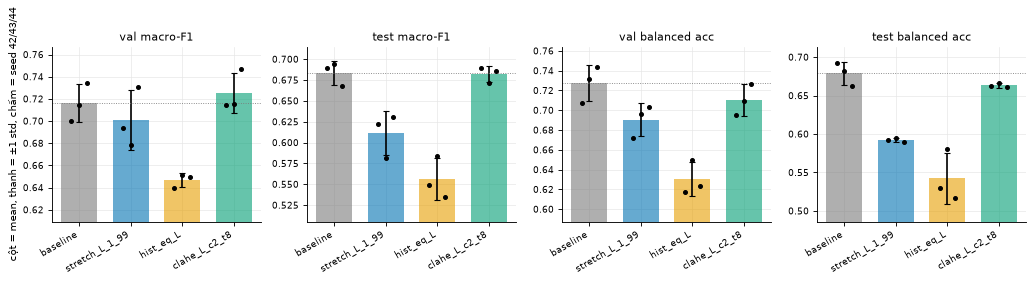

In [11]:
R.fig_results(KEY);

**F1 và recall từng lớp trên test** (trung bình 3 seed). Lớp `df`, `vasc` có ít ảnh nên dao động lớn.

In [12]:
display(R.per_class(KEY, 'test'))

F1                                          recall                                       
config baseline stretch_L_1_99 hist_eq_L clahe_L_c2_t8 baseline stretch_L_1_99 hist_eq_L clahe_L_c2_t8
lớp                                                                                                   
akiec     0.584          0.526     0.496         0.599    0.581          0.485     0.439         0.530
bcc       0.755          0.660     0.541         0.704    0.783          0.689     0.553         0.786
bkl       0.674          0.626     0.592         0.671    0.702          0.668     0.648         0.720
df        0.630          0.395     0.382         0.617    0.551          0.333     0.348         0.522
mel       0.551          0.483     0.444         0.527    0.565          0.465     0.443         0.471
nv        0.916          0.906     0.896         0.918    0.907          0.907     0.892         0.924
vasc      0.676          0.683     0.542         0.741    0.667          0.598     0.471         0.690

**Tác động riêng lên nhóm ảnh bị cờ.** DiD = Δ lỗi nhóm cờ − Δ lỗi phần còn lại. DiD âm nghĩa là phép xử lý giúp riêng nhóm cờ nhiều hơn phần còn lại.

In [13]:
display(R.target_group_effect(D, KEY).round(4))

,split,config,n nhóm cờ,lỗi baseline nhóm cờ,Δ lỗi nhóm cờ,Δ lỗi còn lại,DiD,CI thấp,CI cao
0,val,stretch_L_1_99,71,0.2676,-0.0282,0.0176,-0.0458,-0.1290,0.0296
1,val,hist_eq_L,71,0.2676,-0.0094,0.0322,-0.0416,-0.1205,0.0371
2,val,clahe_L_c2_t8,71,0.2676,-0.0047,-0.0113,0.0066,-0.0498,0.0722
3,test,stretch_L_1_99,89,0.2809,0.0000,0.0279,-0.0279,-0.0827,0.0266
4,test,hist_eq_L,89,0.2809,0.1236,0.0477,0.0759,-0.0039,0.1592
5,test,clahe_L_c2_t8,89,0.2809,-0.0112,-0.0009,-0.0104,-0.0595,0.0411


## 7. So sánh dự đoán trên mẫu 100 ảnh gặp vấn đề

**Cách lấy mẫu:** rút ngẫu nhiên 100 ảnh bị cờ ở val + test, seed 42, mỗi lesion một ảnh, không nhìn dự đoán. Dùng cả val vì ảnh bị cờ ở test có thể không đủ 100, và đây là thống kê ngoài mẫu huấn luyện.

**Trước** là dự đoán của baseline, **sau** là mô hình cùng seed huấn luyện trên ảnh đã xử lý. Ba dòng `baseline seed A→B` cho biết bao nhiêu ảnh đổi đúng/sai dù không xử lý gì, đó là mức cần vượt.

In [14]:
S = R.sample_100(D, KEY)
SD = R.sample_detail(S, KEY)
print(S.split_exp.value_counts().to_dict(), S.dx.value_counts().to_dict())
display(R.sample_summary(SD, KEY).round(4))

{'test': 60, 'val': 40} {'nv': 36, 'bkl': 24, 'bcc': 17, 'akiec': 14, 'mel': 5, 'df': 4}


,so sánh,đúng trước,đúng sau,sai→đúng,đúng→sai,ròng,McNemar p
0,stretch_L_1_99 | seed 42,70,71,13,12,1,1.0000
1,stretch_L_1_99 | seed 43,70,74,14,10,4,0.5413
2,stretch_L_1_99 | seed 44,77,74,9,12,-3,0.6636
3,stretch_L_1_99 | đa số 3 seed,73,76,10,7,3,0.6291
4,hist_eq_L | seed 42,70,63,9,16,-7,0.2295
5,hist_eq_L | seed 43,70,63,13,20,-7,0.2962
6,hist_eq_L | seed 44,77,61,6,22,-16,0.0037
7,hist_eq_L | đa số 3 seed,73,60,7,20,-13,0.0192
8,clahe_L_c2_t8 | seed 42,70,75,11,6,5,0.3323
9,clahe_L_c2_t8 | seed 43,70,68,8,10,-2,0.8145


**Xác suất của lớp đúng thay đổi thế nào.** Kiểm định dấu hạng Wilcoxon ghép theo ảnh, hiệu chỉnh Holm.

,config,Δ prob TB,Δ prob trung vị,số ảnh tăng,số ảnh giảm,Wilcoxon p,p Holm
0,stretch_L_1_99,-0.0022,-0.0075,43,57,0.6749,1.0000
1,hist_eq_L,-0.0704,-0.0109,41,59,0.0233,0.0698
2,clahe_L_c2_t8,-0.0017,-0.0006,48,52,0.6060,1.0000


,n,đúng trước (đa số),đúng sau (đa số)
dx,,,
akiec,14,9,9
bcc,17,13,12
bkl,24,16,15
df,4,2,2
mel,5,1,2
nv,36,32,33


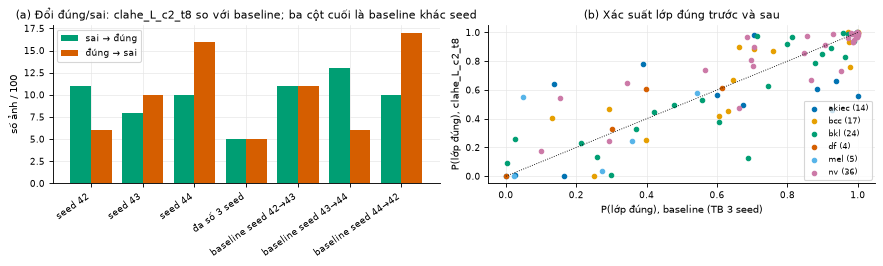

In [15]:
display(R.prob_change(SD, KEY).round(4))
display(R.sample_by_class(SD, BEST))
R.fig_sample(SD, KEY, BEST);

**Ảnh đổi đúng/sai theo đa số 3 seed** (cấu hình `BEST`, tối đa 4 ảnh mỗi chiều, lấy theo thứ tự `image_id`).

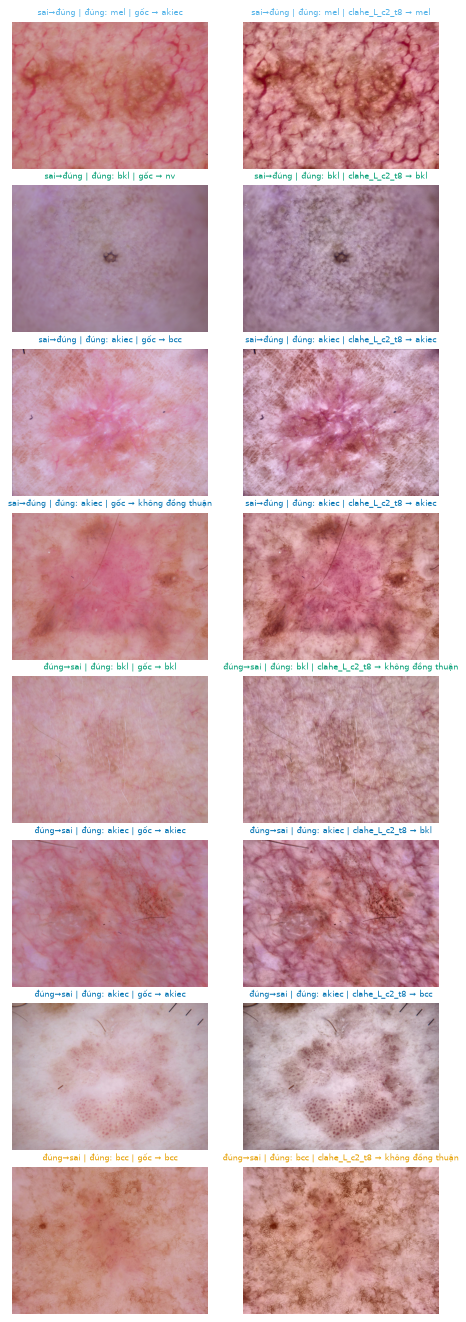

In [16]:
R.fig_sample_grid(SD, KEY, BEST);

## 8. Nhận xét

Số liệu lấy từ các bảng ở mục 2–7, file gốc ở `outputs/rerun_2.5/`. Trục y của hình kết quả ở mục 6 không bắt đầu từ 0 nên cột nhìn chênh nhiều hơn thực tế, cần đọc số trong bảng.

**Quan sát**

- **Mức độ vấn đề:** 435/10.015 ảnh bị cờ (4,34%). Tỉ lệ đổi từ 1,41% đến 13,56% khi ngưỡng đi từ 15 đến 30, nên con số phụ thuộc ngưỡng.
- **Độ tin cậy của cờ:** trong 24 ảnh đã soát, mask Otsu sai ở 10 ảnh (41,7%), đúng 9, đúng một phần 5 (AI đánh giá, cần người xác nhận). Nhóm cờ vì vậy lẫn cả ảnh do bộ đo sai.
- **Bằng chứng độc lập:** nhóm cờ có độ lệch chuẩn mức xám 12,24 so với 25,96 (Cliff's δ −0,902), khoảng phân vị 5–95 là 38 so với 83 (δ −0,889). Toàn ảnh của nhóm này có dải sáng hẹp hơn thật, không chỉ do mask.
- **Nhóm ảnh:** yếu tố liên quan mạnh nhất là lớp bệnh (Cramér's V 0,180): `bcc` 15,37%, `akiec` 12,84%, `bkl` 10,37%, so với `nv` 2,51% và `mel` 1,35%. Theo vùng cơ thể, `hand` 15,56%, `face` 15,03%. Lỗi baseline ở nhóm cờ là 26,8% (val) và 28,1% (test).
- **Macro-F1, 3 seed, baseline test 0,6837 ± 0,0141:**

| Cấu hình | Δ val (CI95) | Kết luận val | Δ test (CI95) | Kết luận test | Δ bal. acc test |
|---|---|---|---|---|---|
| `stretch_L_1_99` | −0,0153 [−0,0500; +0,0197] | không khác biệt rõ | −0,0724 [−0,1045; −0,0397] | **tệ hơn rõ** | −0,0870 |
| `hist_eq_L` | −0,0694 [−0,1113; −0,0335] | **tệ hơn rõ** | −0,1274 [−0,1631; −0,0888] | **tệ hơn rõ** | −0,1370 |
| `clahe_L_c2_t8` | +0,0092 [−0,0177; +0,0341] | không khác biệt rõ | −0,0011 [−0,0274; +0,0243] | không khác biệt rõ | −0,0159 |

- **Theo lớp trên test:** `stretch_L_1_99` làm F1 của `df` từ 0,630 xuống 0,395. `hist_eq_L` làm F1 của `bcc` từ 0,755 xuống 0,541. `clahe_L_c2_t8` làm recall của `mel` từ 0,565 xuống 0,471, recall `bcc` gần như giữ nguyên (0,783 và 0,786), F1 `vasc` từ 0,676 lên 0,741. Lớp `df`, `vasc` ít ảnh nên dao động lớn.
- **Riêng nhóm cờ:** CI95 của DiD chứa 0 ở cả 6 so sánh. Với `clahe_L_c2_t8`, DiD là +0,0066 (val) và −0,0104 (test). Với `hist_eq_L` trên test, lỗi nhóm cờ tăng 12,4 điểm phần trăm so với 4,8 của phần còn lại (DiD +0,0759, CI [−0,0039; +0,1592]).
- **Mẫu 100 ảnh, theo đa số 3 seed (baseline đúng 73 ảnh):**
  - `clahe_L_c2_t8`: 73→73 (5 sai→đúng, 5 đúng→sai, McNemar p = 1,0). Theo từng seed, mức ròng là +5, −2, −6.
  - `stretch_L_1_99`: 73→76 (10 và 7, p = 0,63).
  - `hist_eq_L`: 73→60 (7 và 20, p = 0,019). Theo từng seed, mức ròng là −7, −7, −16.
  - Đổi seed của chính baseline cho mức ròng từ −7 đến +7 ảnh, nên chỉ `hist_eq_L` seed 44 vượt khỏi dao động này.
- Thay đổi xác suất lớp đúng không có ý nghĩa sau Holm ở cả 3 cấu hình (p Holm 1,0; 0,0698; 1,0).

**Đối chiếu giả thuyết**

- "Hai phép toàn cục có thể làm giảm macro-F1" **được ủng hộ**: `hist_eq_L` tệ hơn rõ trên cả val và test. `stretch_L_1_99` tệ hơn rõ trên test, còn trên val chưa đạt ngưỡng dù cả 3 seed đều giảm.
- "CLAHE trung tính so với baseline" **phù hợp** theo quy tắc 2.5.0.
- Không cấu hình nào cải thiện macro-F1 trên test.

**Diễn giải (thận trọng)**

- Đo trên ảnh trước/sau, `hist_eq_L` tăng độ chênh da–tổn thương của nhóm cờ từ 16,5 lên 100,4, nhưng đồng thời làm lệch màu mạnh nhất (dE76 23,6) và tăng σ nhiễu sau resize 5,5 lần. `stretch_L_1_99` cho dE76 13,0 và nhiễu tăng 3,5 lần. Việc tăng chỉ số tương phản không đi kèm kết quả phân loại tốt hơn. Biến dạng màu và khuếch đại nhiễu có thể là một phần nguyên nhân, nhưng thí nghiệm này không tách riêng được hai yếu tố.
- Phép xử lý áp lên mọi ảnh, trong khi chỉ 4,34% ảnh bị cờ, nên tác hại lên phần còn lại có thể lấn át lợi ích nếu có ở nhóm cờ. Với `stretch_L_1_99` trên test, lỗi nhóm cờ không đổi còn phần còn lại tăng 2,8 điểm phần trăm, phù hợp với cách giải thích này nhưng DiD chưa đủ rõ.
- `clahe_L_c2_t8` chỉ đưa chỉ số tương phản của nhóm cờ từ 16,5 lên 19,9, nên kết quả trung tính có thể một phần vì phép này thay đổi ít ở đúng đại lượng cần cải thiện.
- Nhóm cờ tập trung ở `bcc`, `akiec`, `bkl`, nên tỉ lệ lỗi cao có thể đến từ độ khó của các lớp này hơn là từ tương phản. Đây là liên quan, chưa phải nguyên nhân.

**Hạn chế**

- Mask Otsu sai ở một phần lớn mẫu soát, nên "nhóm cờ" và mẫu 100 ảnh không hoàn toàn là ảnh tương phản thấp thật.
- Mẫu 100 ảnh có 40 ảnh từ val, mà `clahe_L_c2_t8` được chọn theo val.
- "Sau" là mô hình train lại trên ảnh đã xử lý, nên chênh lệch gồm cả tác động của ảnh và của việc train lại.
- Recall `mel` giảm với CLAHE chỉ là số trung bình 3 seed, chưa kiểm định riêng nên chưa kết luận được.

**Quyết định cho pipeline:** không đưa `hist_eq_L` và `stretch_L_1_99` vào pipeline. `clahe_L_c2_t8` không có lợi đo được trên macro-F1 nên cũng chưa có cơ sở để đưa vào, và cần xem thêm recall `mel` nếu nhóm vẫn muốn thử ở 2.6.